In [1]:
!pip install -q kagglehub

import kagglehub

# Download Animals-10
path = kagglehub.dataset_download("alessiocorrado99/animals10")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'animals10' dataset.
Downloaded to: /kaggle/input/animals10


In [2]:
import os
base = "/kaggle/input/animals10"
print(os.listdir(base))

# Check inside raw-img folder
import pathlib
for root, dirs, files in os.walk(base):
    level = root.count(os.sep)
    if level < 5:
        print(root, "->", len(files), "files, folders:", dirs[:12])
    if level > 4:
        break

['translate.py', 'raw-img']
/kaggle/input/animals10 -> 1 files, folders: ['raw-img']
/kaggle/input/animals10/raw-img -> 0 files, folders: ['cavallo', 'pecora', 'elefante', 'gatto', 'scoiattolo', 'gallina', 'ragno', 'mucca', 'cane', 'farfalla']


In [3]:
import os
from pathlib import Path

data_dir = "/kaggle/input/animals10/raw-img"

for animal in sorted(os.listdir(data_dir)):
    folder = os.path.join(data_dir, animal)
    if os.path.isdir(folder):
        count = len(os.listdir(folder))
        print(f"{animal:12} -> {count} images")

cane         -> 4863 images
cavallo      -> 2623 images
elefante     -> 1446 images
farfalla     -> 2112 images
gallina      -> 3098 images
gatto        -> 1668 images
mucca        -> 1866 images
pecora       -> 1820 images
ragno        -> 4821 images
scoiattolo   -> 1862 images


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
import os

data_dir = "/kaggle/input/animals10/raw-img"
IMG_SIZE = 224
BATCH = 32

# Load data - 80% train, 20% validation
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='training', seed=123
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='validation', seed=123
)

class_names = train_ds.class_names
print("Classes:", class_names)
print("Num classes:", len(class_names))

# Speed up
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Transfer Learning - MobileNetV2
base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1, input_shape=(224,224,3)),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# Train
history = model.fit(train_ds, validation_data=val_ds, epochs=8)

# Save
model.save("animals10_model.keras")
print("Saved! Done training")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/animals10/raw-img'

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [9]:
import kagglehub, os, glob
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Download and auto-find folder
path = kagglehub.dataset_download("alessiocorrado99/animals10")
print("Downloaded to:", path)

# Find raw-img automatically
candidates = glob.glob(os.path.join(path, "**", "raw-img"), recursive=True)
if candidates:
    data_dir = candidates[0]
else:
    data_dir = path
print("Using data_dir:", data_dir)
print(os.listdir(data_dir))

# 2. Train
IMG_SIZE = 224
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='training', seed=123
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='validation', seed=123
)

print("Classes:", train_ds.class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1, input_shape=(224,224,3)),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(train_ds.class_names), activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=8)
model.save("animals10_model.keras")
print("Saved! Done training")

Using Colab cache for faster access to the 'animals10' dataset.
Downloaded to: /kaggle/input/animals10
Using data_dir: /kaggle/input/animals10/raw-img
['cavallo', 'pecora', 'elefante', 'gatto', 'scoiattolo', 'gallina', 'ragno', 'mucca', 'cane', 'farfalla']
Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Classes: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


AttributeError: '_PrefetchDataset' object has no attribute 'class_names'

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_dir = "/kaggle/input/animals10/raw-img"
IMG_SIZE = 224
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='training', seed=123
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='validation', seed=123
)

# Save names BEFORE cache - this is the fix
class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1, input_shape=(224,224,3)),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=8)
model.save("animals10_model.keras")
print("Saved! Done training")

Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Classes: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
Epoch 1/8
438/655 ━━━━━━━━━━━━━━━━━━━━ 27s 125ms/step - accuracy: 0.8203 - loss: 0.6256

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_dir = "/kaggle/input/animals10/raw-img"
IMG_SIZE = 224
BATCH = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='training', seed=123
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    label_mode='categorical', validation_split=0.2, subset='validation', seed=123
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

# NO .cache() this time - this was crashing RAM
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base.trainable = False

model = models.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1, input_shape=(224,224,3)),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=8)
model.save("animals10_model.keras")
print("Saved! Done training")

Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Classes: ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1309/1309 ━━━━━━━━━━━━━━━━━━━━ 99s 65ms/step - accuracy: 0.9351 - loss: 0.2283 - val_accuracy: 0.9639 - val_loss: 0.1320
Epoch 2/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.9636 - loss: 0.1215 - val_accuracy: 0.9652 - val_loss: 0.1253
Epoch 3/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.9688 - loss: 0.1023 - val_accuracy: 0.9605 - val_loss: 0.1444
Epoch 4/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 40s 31ms/step - accuracy: 0.9734 - loss: 0.0875 - val_accuracy: 0.9631 - val_loss: 0.1410
Epoch 5/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 40s 30ms/step - accuracy: 0.9756 - loss: 0.0794 - val_accuracy: 0.9668 - val_loss: 0.1319
Epoch 6/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 43s 33ms/step - accuracy: 0.9758 - loss: 0.0752 - val_accuracy: 0.9637 - val_loss: 0.1403
Epoch 7/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9796 - loss: 0.0667 - val_accuracy: 0.9635 - val_loss: 0.1489
Epoch 8/8
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9786 - loss: 0.0654 - va

In [2]:
import tensorflow as tf
import numpy as np
from google.colab import files

# Upload one animal picture
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

img = tf.keras.utils.load_img(img_path, target_size=(224,224))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

model = tf.keras.models.load_model("animals10_model.keras")
pred = model.predict(img_array)
classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
print("This animal na:", classes[np.argmax(pred)])
print("Confidence:", float(np.max(pred)*100), "%")

Saving animals10_model.keras to animals10_model (1).keras


UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x784eca1736f0>

In [5]:
import tensorflow as tf
import numpy as np
import glob, os

# Find where the dataset really dey - no guess
all_imgs = glob.glob("/kaggle/input/**/*.jpg", recursive=True) + glob.glob("/kaggle/input/**/*.jpeg", recursive=True) + glob.glob("/kaggle/input/**/*.png", recursive=True)
print("Total pictures found:", len(all_imgs))
print("First one:", all_imgs[0] if all_imgs else "None")

# Pick one dog picture if we see am, if not pick the first one
img_path = None
for p in all_imgs:
    if "cane" in p.lower():
        img_path = p
        break
if img_path is None:
    img_path = all_imgs[0]

print("Testing with:", img_path)

img = tf.keras.utils.load_img(img_path, target_size=(224,224))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

model = tf.keras.models.load_model("animals10_model.keras")
pred = model.predict(img_array)
classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
print("This animal na:", classes[np.argmax(pred)])
print("Confidence:", float(np.max(pred)*100), "%")

Total pictures found: 26179
First one: /kaggle/input/animals10/raw-img/pecora/eb31b9092bf61c22d2524518b7444f92e37fe5d404b0144390f8c078a0eabd_640.jpg
Testing with: /kaggle/input/animals10/raw-img/cane/OIP-6p-HHjhphvPW9vf63Gg_jAHaGQ.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
This animal na: cane
Confidence: 98.94877624511719 %


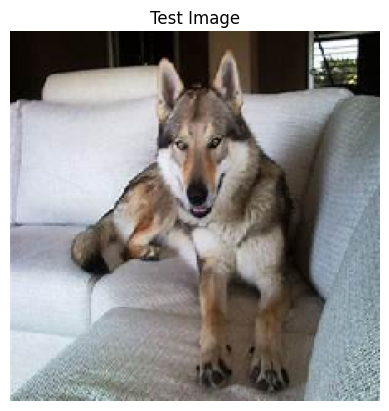

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
This animal na: cane
Confidence: 98.94877624511719 %


In [6]:
import tensorflow as tf
import numpy as np
import glob
import matplotlib.pyplot as plt

# Find one dog picture
all_imgs = glob.glob("/kaggle/input/**/*.jpg", recursive=True) + glob.glob("/kaggle/input/**/*.jpeg", recursive=True)
img_path = None
for p in all_imgs:
    if "cane" in p.lower():
        img_path = p
        break

# Load and show the picture
img = tf.keras.utils.load_img(img_path, target_size=(224,224))
plt.imshow(img)
plt.axis('off')
plt.title("Test Image")
plt.show()

# Predict
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

model = tf.keras.models.load_model("animals10_model.keras")
pred = model.predict(img_array)
classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']
print("This animal na:", classes[np.argmax(pred)])
print("Confidence:", float(np.max(pred)*100), "%")

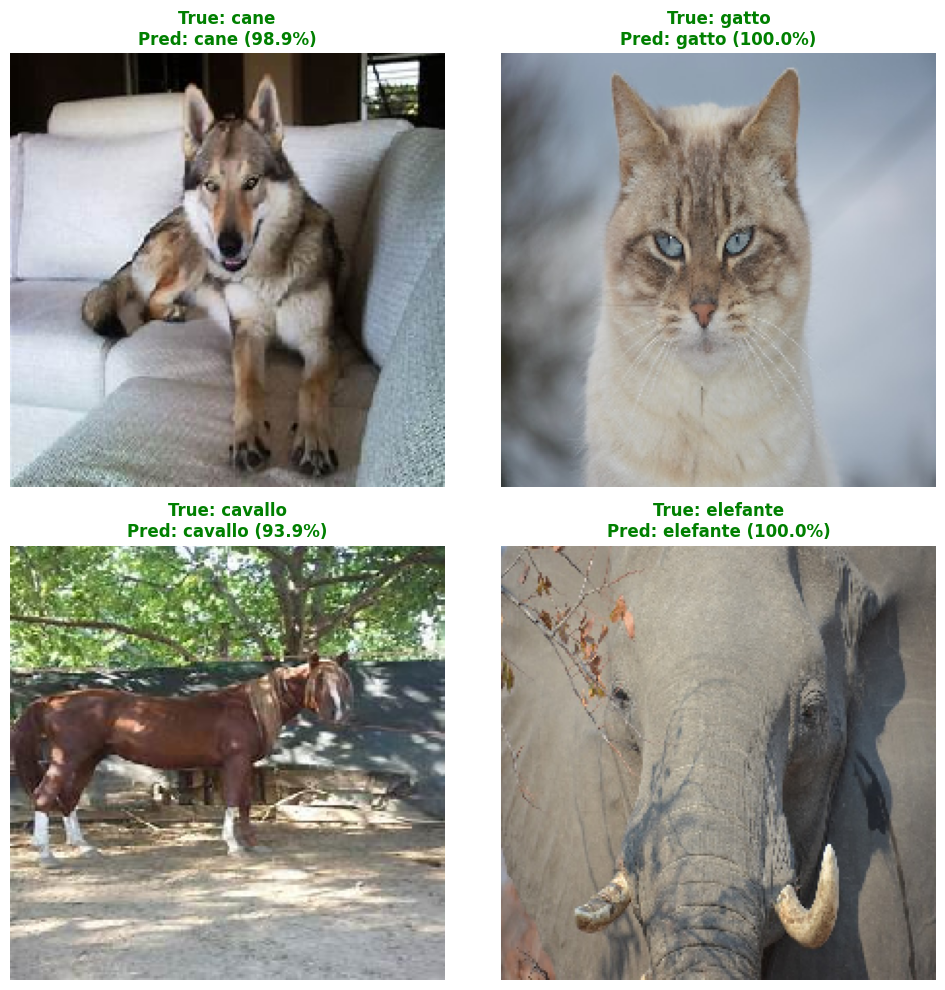

In [7]:
import tensorflow as tf
import numpy as np
import glob
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("animals10_model.keras")
classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']

# Pick 4 different animals
want = ['cane', 'gatto', 'cavallo', 'elefante']  # dog, cat, horse, elephant
all_imgs = glob.glob("/kaggle/input/**/*.jpg", recursive=True) + glob.glob("/kaggle/input/**/*.jpeg", recursive=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, animal in zip(axes.flat, want):
    # Find one picture for this animal
    img_path = None
    for p in all_imgs:
        if f"/{animal}/" in p.lower():
            img_path = p
            break

    img = tf.keras.utils.load_img(img_path, target_size=(224,224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    pred = model.predict(img_array, verbose=0)
    pred_class = classes[np.argmax(pred)]
    conf = float(np.max(pred)*100)

    ax.imshow(img)
    ax.axis('off')
    # Green if correct, red if wrong
    color = 'green' if pred_class == animal else 'red'
    ax.set_title(f"True: {animal}\nPred: {pred_class} ({conf:.1f}%)", color=color, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

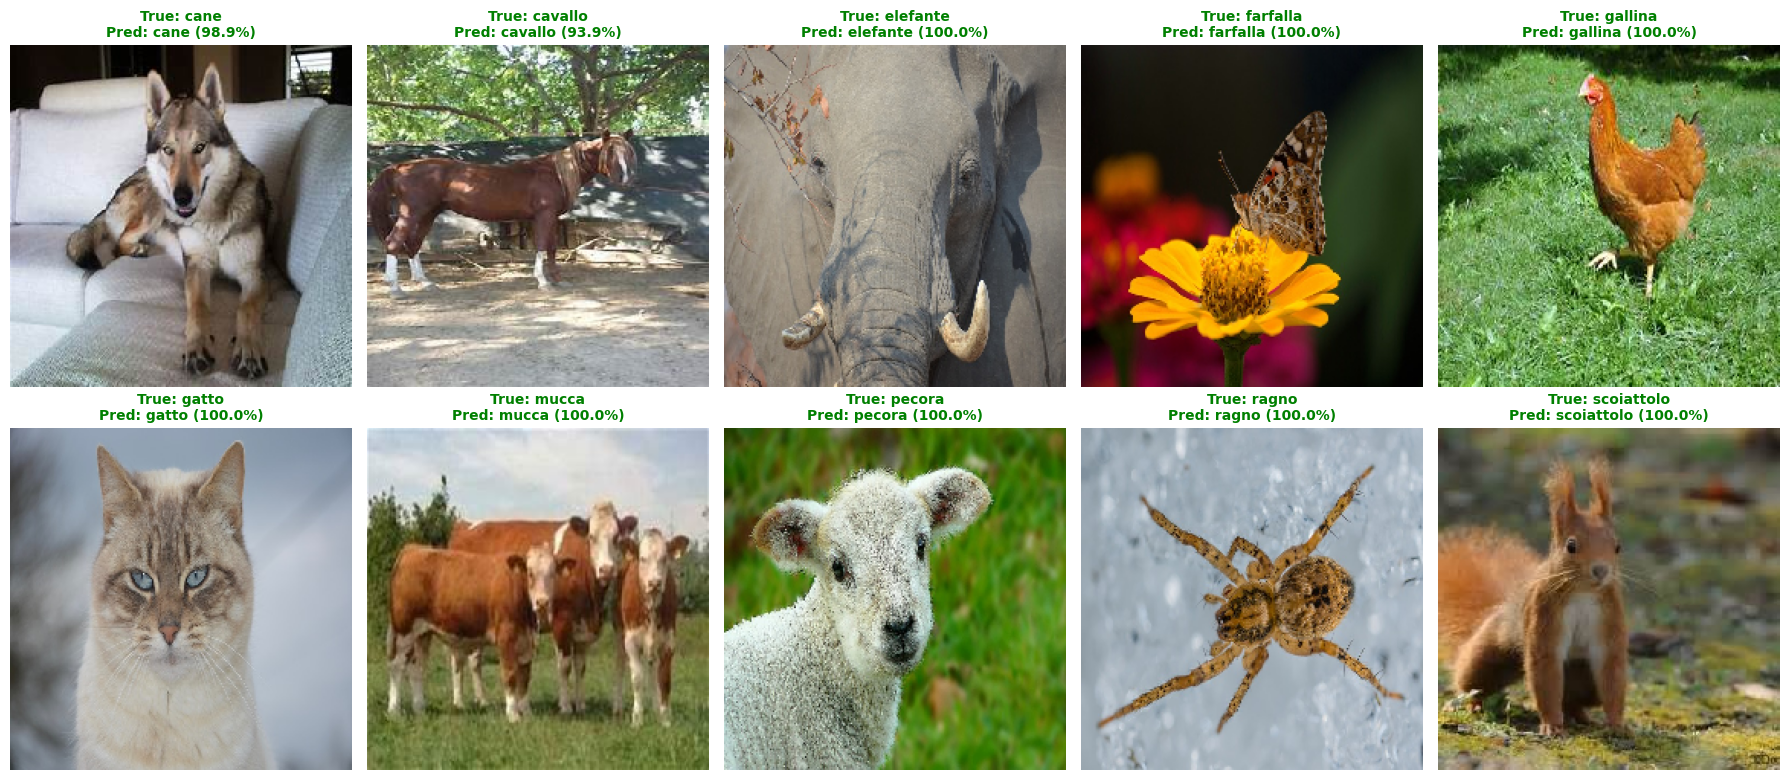

In [8]:
import tensorflow as tf
import numpy as np
import glob
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("animals10_model.keras")
classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']

all_imgs = glob.glob("/kaggle/input/**/*.jpg", recursive=True) + glob.glob("/kaggle/input/**/*.jpeg", recursive=True) + glob.glob("/kaggle/input/**/*.png", recursive=True)

# 2 rows, 5 columns = 10 animals
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, animal in zip(axes.flat, classes):
    img_path = None
    for p in all_imgs:
        if f"/{animal}/" in p.lower():
            img_path = p
            break

    img = tf.keras.utils.load_img(img_path, target_size=(224,224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    pred = model.predict(img_array, verbose=0)
    pred_class = classes[np.argmax(pred)]
    conf = float(np.max(pred)*100)

    ax.imshow(img)
    ax.axis('off')
    color = 'green' if pred_class == animal else 'red'
    ax.set_title(f"True: {animal}\nPred: {pred_class} ({conf:.1f}%)", color=color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Found 26179 files belonging to 10 classes.
Using 5235 files for validation.


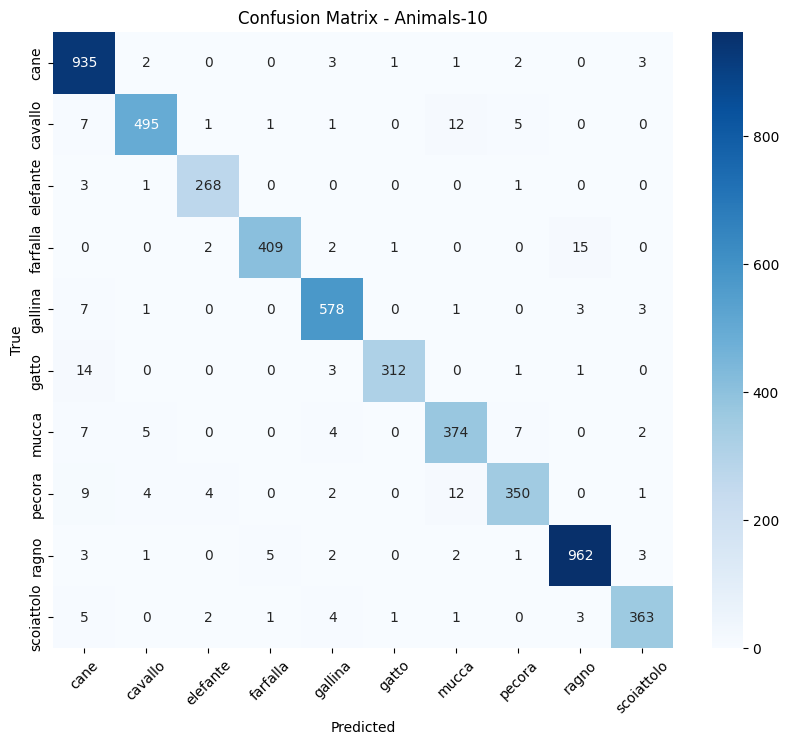

              precision    recall  f1-score   support

        cane       0.94      0.99      0.97       947
     cavallo       0.97      0.95      0.96       522
    elefante       0.97      0.98      0.97       273
    farfalla       0.98      0.95      0.97       429
     gallina       0.96      0.97      0.97       593
       gatto       0.99      0.94      0.97       331
       mucca       0.93      0.94      0.93       399
      pecora       0.95      0.92      0.93       382
       ragno       0.98      0.98      0.98       979
  scoiattolo       0.97      0.96      0.96       380

    accuracy                           0.96      5235
   macro avg       0.97      0.96      0.96      5235
weighted avg       0.96      0.96      0.96      5235



In [9]:
import tensorflow as tf
import numpy as np
import glob, os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

model = tf.keras.models.load_model("animals10_model.keras")
classes = ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']

# Find dataset folder
base = None
for p in glob.glob("/kaggle/input/**/cane", recursive=True):
    base = os.path.dirname(p)
    break

val_ds = tf.keras.utils.image_dataset_from_directory(
    base,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=16
)

y_true = []
y_pred = []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Animals-10")
plt.xticks(rotation=45)
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))